# Aula 6: desocupação por sexo, horas de cuidado e um estado

Nesta aula você junta as duas **Tabelas 5** (composição da desocupação por sexo em 2012 e 2026), compara ano a ano e cruza com a **Tabela 1.1.1** do IBGE (horas semanais de cuidados e afazeres domésticos, 2022).

**O que vamos ver**

1. Abrir e juntar as duas Tabelas 5
2. Comparativo 2012 × 2026 e gráficos dos dois anos
3. Limpar a Tabela 1.1.1 e juntar pelos nomes dos estados
4. Comparar desocupação e carga de cuidado
5. Análise quantitativa e qualitativa de **Rondônia**

In [60]:
# No terminal, uma vez: python -m pip install pandas matplotlib seaborn xlrd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

In [61]:
path_2012 = r"C:\Users\janai\OneDrive\Documentos\python-class\dados\Tabela5-sem_emprego_2012.csv"
path_2026 = r"C:\Users\janai\OneDrive\Documentos\python-class\dados\Tabela5-sem_emprego_2026.csv"
path_horas = r"C:\Users\janai\OneDrive\Documentos\python-class\dados\Pandas_Aula1_2\mulheres_ibge\Tabela 1.1.1.xls"

ESTADO = "Minas Gerais"

## 1. Abrir e juntar as duas Tabelas 5

Os arquivos são CSV com `;`, vírgula decimal e BOM UTF-8. Os valores são a **participação de homens e mulheres entre as pessoas desocupadas** no 1º trimestre (não é a taxa de desemprego).

In [62]:
t2012 = pd.read_csv(path_2012, sep=";", decimal=",", encoding="utf-8-sig")
t2026 = pd.read_csv(path_2026, sep=";", decimal=",", encoding="utf-8-sig")

t2012 = t2012.rename(columns={
    "Desocupados - homens (2012 T1)": "homens_2012",
    "Desocupados - mulheres (2012 T1)": "mulheres_2012",
})
t2026 = t2026.rename(columns={
    "Desocupados - homens (2026 T1)": "homens_2026",
    "Desocupados - mulheres (2026 T1)": "mulheres_2026",
})

display(t2012.head())
display(t2026.head())

,Sigla,Código,Estado,homens_2012,mulheres_2012
0,AC,12,Acre,45.3,54.7
1,AL,27,Alagoas,44.7,55.3
2,AM,13,Amazonas,47.5,52.5
3,AP,16,Amapá,48.1,51.9
4,BA,29,Bahia,43.8,56.2


,Sigla,Código,Estado,homens_2026,mulheres_2026
0,AC,12,Acre,53.2,46.8
1,AL,27,Alagoas,50.7,49.3
2,AM,13,Amazonas,46.8,53.2
3,AP,16,Amapá,51.1,48.9
4,BA,29,Bahia,44.7,55.3


In [63]:
comp = t2012.merge(t2026, on=["Sigla", "Código", "Estado"], how="inner")
comp["var_mulheres_pp"] = (comp["mulheres_2026"] - comp["mulheres_2012"]).round(1)
comp["var_homens_pp"] = (comp["homens_2026"] - comp["homens_2012"]).round(1)
comp = comp.sort_values("var_mulheres_pp", ascending=False).reset_index(drop=True)
comp

,Sigla,Código,Estado,homens_2012,mulheres_2012,homens_2026,mulheres_2026,var_mulheres_pp,var_homens_pp
0,RO,11,Rondônia,43.4,56.6,33.0,67.0,10.4,-10.4
1,TO,17,Tocantins,55.3,44.7,46.2,53.8,9.1,-9.1
2,SE,28,Sergipe,46.5,53.5,40.3,59.7,6.2,-6.2
3,RN,24,Rio Grande do Norte,51.0,49.0,48.2,51.8,2.8,-2.8
4,MS,50,Mato Grosso do Sul,47.2,52.8,45.3,54.7,1.9,-1.9
5,MT,51,Mato Grosso,44.1,55.9,42.8,57.2,1.3,-1.3
6,AM,13,Amazonas,47.5,52.5,46.8,53.2,0.7,-0.7
7,SP,35,São Paulo,45.4,54.6,46.2,53.8,-0.8,0.8
8,BA,29,Bahia,43.8,56.2,44.7,55.3,-0.9,0.9
9,ES,32,Espírito Santo,46.4,53.6,47.5,52.5,-1.1,1.1


## 2. Comparativo ano a ano e gráficos dos dois períodos

A variação está em **pontos percentuais** (pp): participação das mulheres entre as pessoas desocupadas em 2026 menos a de 2012.

In [64]:
print("Média nacional simples (média das UFs, não ponderada pela população)")
print("Mulheres 2012:", round(comp["mulheres_2012"].mean(), 1), "%")
print("Mulheres 2026:", round(comp["mulheres_2026"].mean(), 1), "%")
print("Variação média:", round(comp["var_mulheres_pp"].mean(), 1), "pp")
print()
print("Maior alta da participação feminina:")
print(comp.iloc[0][["Estado", "mulheres_2012", "mulheres_2026", "var_mulheres_pp"]].to_string())
print()
print("Maior queda da participação feminina:")
print(comp.iloc[-1][["Estado", "mulheres_2012", "mulheres_2026", "var_mulheres_pp"]].to_string())

Média nacional simples (média das UFs, não ponderada pela população)
Mulheres 2012: 54.6 %
Mulheres 2026: 53.0 %
Variação média: -1.6 pp

Maior alta da participação feminina:
Estado             Rondônia
mulheres_2012          56.6
mulheres_2026          67.0
var_mulheres_pp        10.4

Maior queda da participação feminina:
Estado             Acre
mulheres_2012      54.7
mulheres_2026      46.8
var_mulheres_pp    -7.9


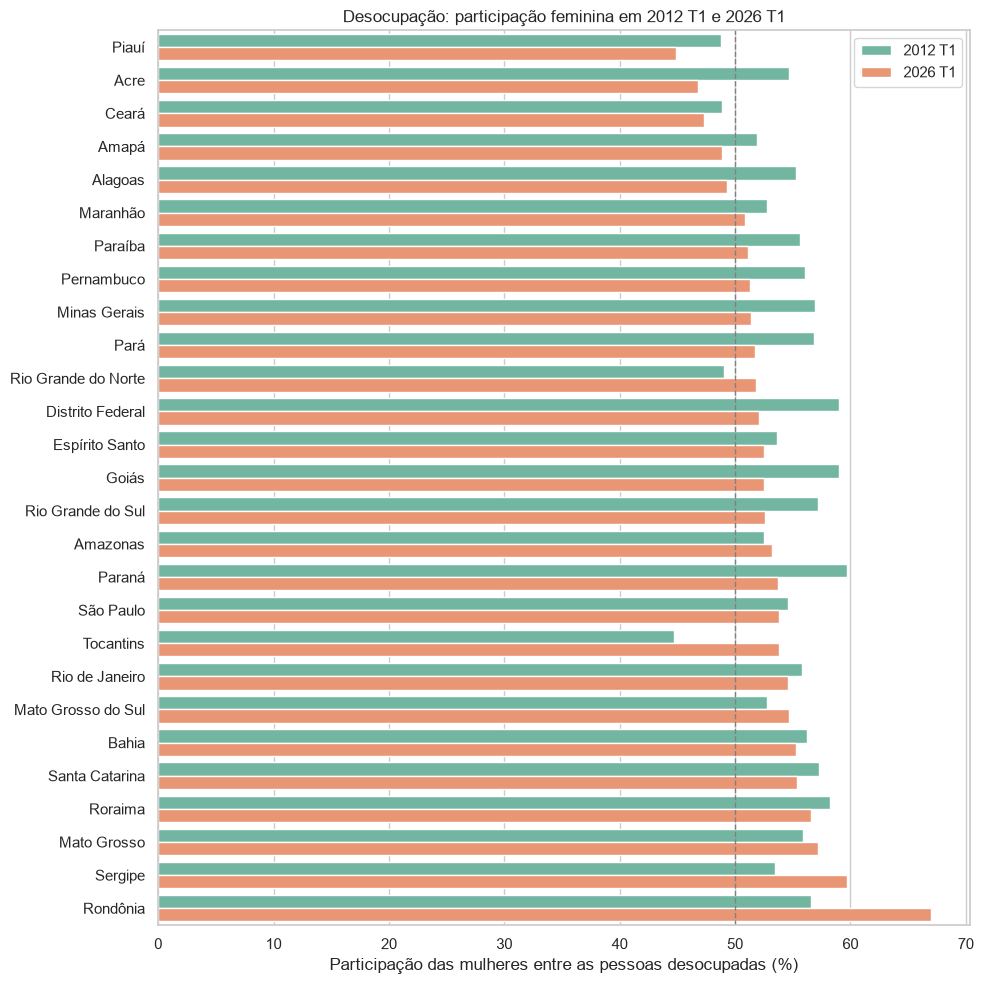

In [65]:
ordem = comp.sort_values("mulheres_2026")["Estado"]
longo = comp.melt(
    id_vars=["Estado", "Sigla"],
    value_vars=["mulheres_2012", "mulheres_2026"],
    var_name="Ano",
    value_name="Participacao_mulheres",
)
longo["Ano"] = longo["Ano"].map({"mulheres_2012": "2012 T1", "mulheres_2026": "2026 T1"})

fig, ax = plt.subplots(figsize=(10, 10))
sns.barplot(
    data=longo,
    y="Estado",
    x="Participacao_mulheres",
    hue="Ano",
    order=ordem,
    ax=ax,
)
ax.axvline(50, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Participação das mulheres entre as pessoas desocupadas (%)")
ax.set_ylabel("")
ax.set_title("Desocupação: participação feminina em 2012 T1 e 2026 T1")
ax.legend(title="")
fig.tight_layout()
plt.show()

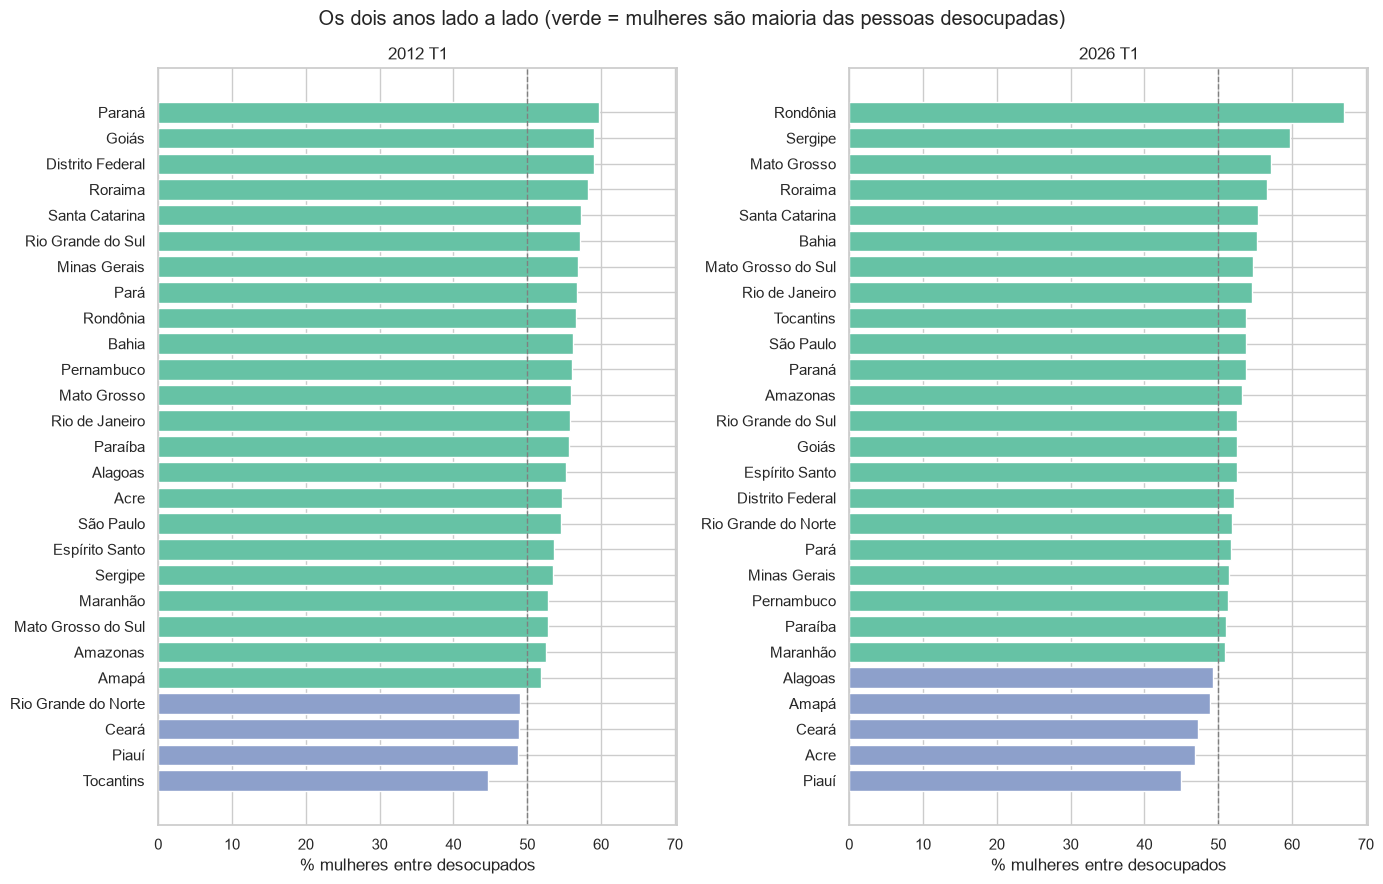

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharex=True)

for ax, col, titulo in [
    (axes[0], "mulheres_2012", "2012 T1"),
    (axes[1], "mulheres_2026", "2026 T1"),
]:
    dados = comp.sort_values(col)
    cores = ["#66c2a5" if v >= 50 else "#8da0cb" for v in dados[col]]
    ax.barh(dados["Estado"], dados[col], color=cores)
    ax.axvline(50, color="gray", linestyle="--", linewidth=1)
    ax.set_title(titulo)
    ax.set_xlabel("% mulheres entre desocupados")

fig.suptitle("Os dois anos lado a lado (verde = mulheres são maioria das pessoas desocupadas)")
fig.tight_layout()
plt.show()

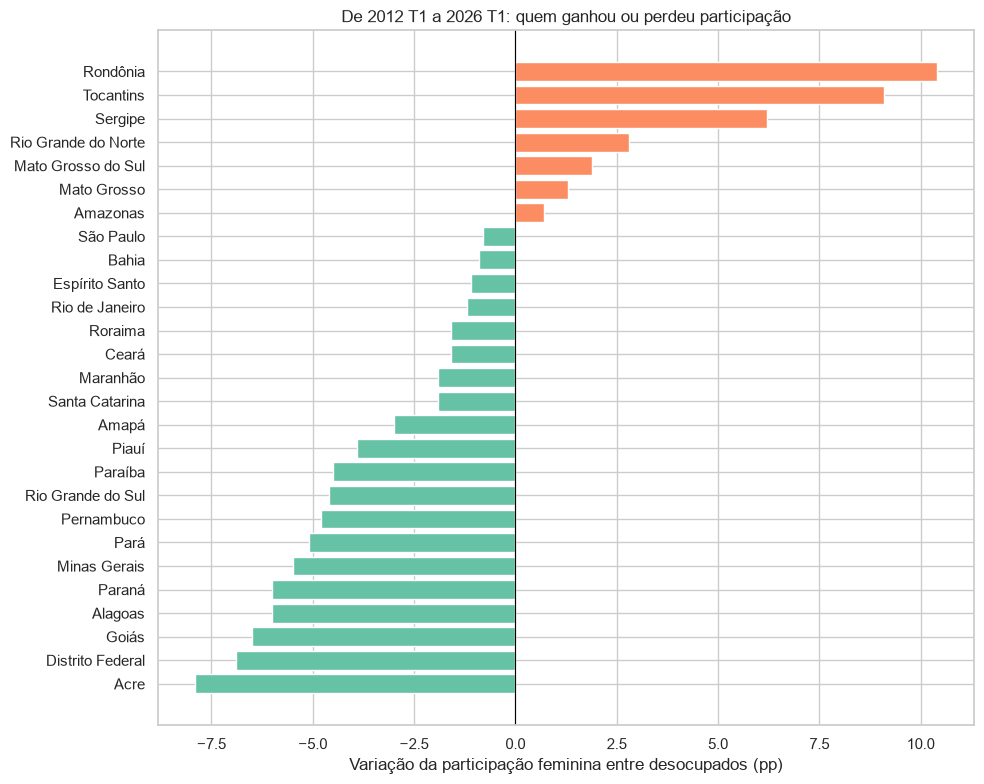

In [67]:
fig, ax = plt.subplots(figsize=(10, 8))
var = comp.sort_values("var_mulheres_pp")
cores = ["#fc8d62" if v > 0 else "#66c2a5" for v in var["var_mulheres_pp"]]
ax.barh(var["Estado"], var["var_mulheres_pp"], color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Variação da participação feminina entre desocupados (pp)")
ax.set_title("De 2012 T1 a 2026 T1: quem ganhou ou perdeu participação")
fig.tight_layout()
plt.show()

## 3. Indicador de cuidado (Tabela 1.1.1)

A planilha do IBGE (PNAD Contínua 2022) traz o **número médio de horas semanais** dedicadas a cuidados de pessoas e/ou afazeres domésticos, por sexo e cor/raça.

As primeiras linhas são título e cabeçalho em várias faixas. Só as linhas de Unidade da Federação entram no cruzamento.

In [68]:
bruto = pd.read_excel(path_horas, engine="xlrd", header=None)
horas = bruto.iloc[8:41].copy()
horas.columns = [
    "Local",
    "horas_total",
    "horas_total_branca",
    "horas_total_preta_parda",
    "horas_homem_branca",
    "horas_homem_preta_parda",
    "horas_mulher_branca",
    "horas_mulher_preta_parda",
]

regioes = ["Brasil", "Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"]
ufs = horas[~horas["Local"].isin(regioes)].copy()
ufs = ufs.rename(columns={"Local": "Estado"})

ufs["horas_homem"] = (ufs["horas_homem_branca"] + ufs["horas_homem_preta_parda"]) / 2
ufs["horas_mulher"] = (ufs["horas_mulher_branca"] + ufs["horas_mulher_preta_parda"]) / 2
ufs["brecha_horas"] = ufs["horas_mulher"] - ufs["horas_homem"]

ufs.head()

,Estado,horas_total,horas_total_branca,horas_total_preta_parda,horas_homem_branca,horas_homem_preta_parda,horas_mulher_branca,horas_mulher_preta_parda,horas_homem,horas_mulher,brecha_horas
10,Rondônia,17.014162,16.727733,17.101523,12.111127,12.54408,20.412887,21.06141,12.327604,20.737149,8.409545
11,Acre,13.606903,13.806929,13.541399,10.79612,9.686983,16.130352,16.710754,10.241551,16.420553,6.179002
12,Amazonas,16.80729,15.987545,16.995493,12.233043,12.822584,18.764969,20.716986,12.527813,19.740977,7.213164
13,Roraima,13.639257,13.651755,13.633606,10.814803,10.476601,16.135877,16.560244,10.645702,16.348061,5.702359
14,Pará,16.474268,16.181627,16.560239,11.524306,11.026707,19.83511,21.591144,11.275506,20.713127,9.437621


In [69]:
cruzado = comp.merge(ufs, on="Estado", how="inner")
print("UFs depois do cruzamento:", len(cruzado))
cruzado[[
    "Estado", "mulheres_2012", "mulheres_2026", "var_mulheres_pp",
    "horas_homem", "horas_mulher", "brecha_horas",
]].round(1)

UFs depois do cruzamento: 27


,Estado,mulheres_2012,mulheres_2026,var_mulheres_pp,horas_homem,horas_mulher,brecha_horas
0,Rondônia,56.6,67.0,10.4,12.327604,20.737149,8.409545
1,Tocantins,44.7,53.8,9.1,11.20824,19.646556,8.438316
2,Sergipe,53.5,59.7,6.2,11.050426,23.689292,12.638866
3,Rio Grande do Norte,49.0,51.8,2.8,11.126598,23.984982,12.858385
4,Mato Grosso do Sul,52.8,54.7,1.9,10.786567,19.067981,8.281414
5,Mato Grosso,55.9,57.2,1.3,9.372694,18.239374,8.86668
6,Amazonas,52.5,53.2,0.7,12.527813,19.740977,7.213164
7,São Paulo,54.6,53.8,-0.8,12.179122,21.269403,9.090281
8,Bahia,56.2,55.3,-0.9,10.76724,22.894924,12.127684
9,Espírito Santo,53.6,52.5,-1.1,11.90808,21.330544,9.422464


## 4. Comparar desocupação e carga de cuidado

Os anos não são iguais (desocupação 2012/2026, horas 2022). Ainda assim dá para ver se estados com mais carga doméstica feminina também têm mais mulheres entre as pessoas desocupadas.

In [70]:
print("Correlação (Pearson)")
print("Horas da mulher × % mulheres desocupadas 2026:",
      round(cruzado["horas_mulher"].corr(cruzado["mulheres_2026"]), 2))
print("Brecha de horas × % mulheres desocupadas 2026:",
      round(cruzado["brecha_horas"].corr(cruzado["mulheres_2026"]), 2))
print("Horas da mulher × variação 2012–2026:",
      round(cruzado["horas_mulher"].corr(cruzado["var_mulheres_pp"]), 2))

Correlação (Pearson)
Horas da mulher × % mulheres desocupadas 2026: -0.09
Brecha de horas × % mulheres desocupadas 2026: -0.07
Horas da mulher × variação 2012–2026: 0.1


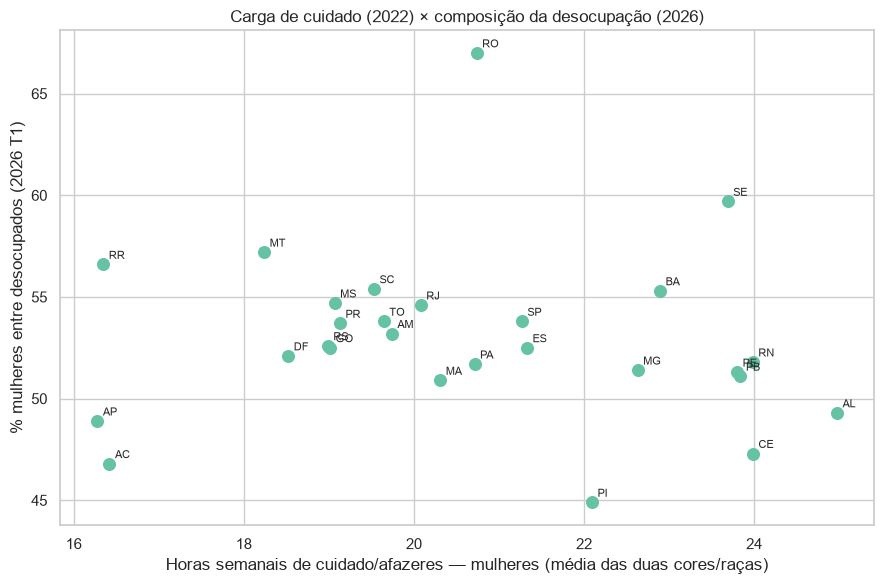

In [71]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(cruzado["horas_mulher"], cruzado["mulheres_2026"], s=70)
for _, r in cruzado.iterrows():
    ax.annotate(r["Sigla"], (r["horas_mulher"], r["mulheres_2026"]),
                textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlabel("Horas semanais de cuidado/afazeres — mulheres (média das duas cores/raças)")
ax.set_ylabel("% mulheres entre desocupados (2026 T1)")
ax.set_title("Carga de cuidado (2022) × composição da desocupação (2026)")
fig.tight_layout()
plt.show()

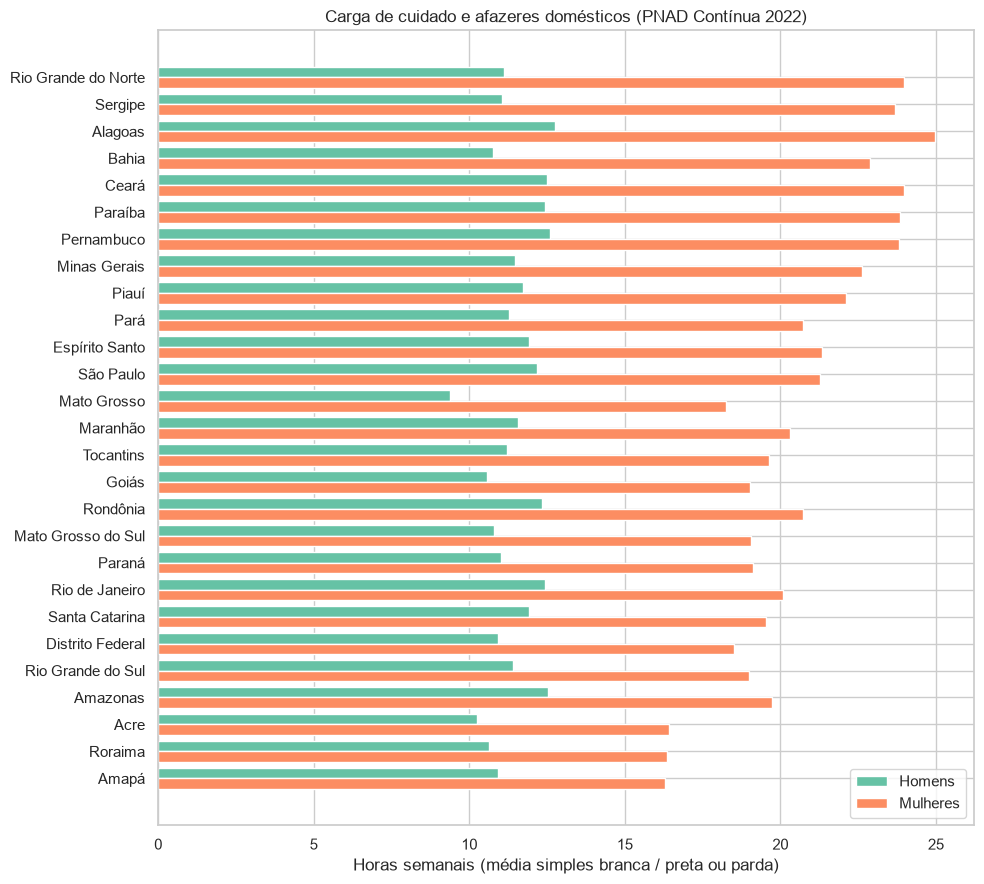

In [72]:
horas_plot = cruzado.sort_values("brecha_horas")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(horas_plot["Estado"], horas_plot["horas_homem"], label="Homens", height=0.4, align="edge")
ax.barh(horas_plot["Estado"], horas_plot["horas_mulher"], label="Mulheres", height=-0.4, align="edge")
ax.set_xlabel("Horas semanais (média simples branca / preta ou parda)")
ax.set_title("Carga de cuidado e afazeres domésticos (PNAD Contínua 2022)")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Um estado: Rondônia

Rondônia é o caso mais extremo no comparativo 2012–2026: a participação das mulheres entre as pessoas desocupadas sobe de forma nítida e chega ao maior valor do país em 2026.

In [73]:
linha = cruzado.loc[cruzado["Estado"] == ESTADO].iloc[0]
brasil = horas.loc[horas["Local"] == "Brasil"].iloc[0]

print(f"=== {ESTADO} ===")
print(f"Participação entre desocupados")
print(f"  2012 T1  homens {linha['homens_2012']:.1f}% | mulheres {linha['mulheres_2012']:.1f}%")
print(f"  2026 T1  homens {linha['homens_2026']:.1f}% | mulheres {linha['mulheres_2026']:.1f}%")
print(f"  Variação mulheres: {linha['var_mulheres_pp']:+.1f} pp")
print()
print("Ranking entre as 27 UFs (1 = maior)")
print("  % mulheres 2012:", int(cruzado["mulheres_2012"].rank(ascending=False)[linha.name]), "º")
print("  % mulheres 2026:", int(cruzado["mulheres_2026"].rank(ascending=False)[linha.name]), "º")
print("  Alta 2012–2026:", int(cruzado["var_mulheres_pp"].rank(ascending=False)[linha.name]), "º")
print()
print("Horas semanais de cuidado/afazeres (2022)")
print(f"  Homem branca: {linha['horas_homem_branca']:.1f} | homem preta ou parda: {linha['horas_homem_preta_parda']:.1f}")
print(f"  Mulher branca: {linha['horas_mulher_branca']:.1f} | mulher preta ou parda: {linha['horas_mulher_preta_parda']:.1f}")
print(f"  Brecha média (mulher − homem): {linha['brecha_horas']:.1f} horas")
print()
print("Brasil (referência, mesmas colunas de horas)")
print(f"  Homem branca: {brasil['horas_homem_branca']:.1f} | homem preta ou parda: {brasil['horas_homem_preta_parda']:.1f}")
print(f"  Mulher branca: {brasil['horas_mulher_branca']:.1f} | mulher preta ou parda: {brasil['horas_mulher_preta_parda']:.1f}")

=== Minas Gerais ===
Participação entre desocupados
  2012 T1  homens 43.1% | mulheres 56.9%
  2026 T1  homens 48.6% | mulheres 51.4%
  Variação mulheres: -5.5 pp

Ranking entre as 27 UFs (1 = maior)
  % mulheres 2012: 7 º
  % mulheres 2026: 19 º
  Alta 2012–2026: 22 º

Horas semanais de cuidado/afazeres (2022)
  Homem branca: 11.3 | homem preta ou parda: 11.6
  Mulher branca: 22.2 | mulher preta ou parda: 23.1
  Brecha média (mulher − homem): 11.2 horas

Brasil (referência, mesmas colunas de horas)
  Homem branca: 11.7 | homem preta ou parda: 11.7
  Mulher branca: 20.4 | mulher preta ou parda: 22.0


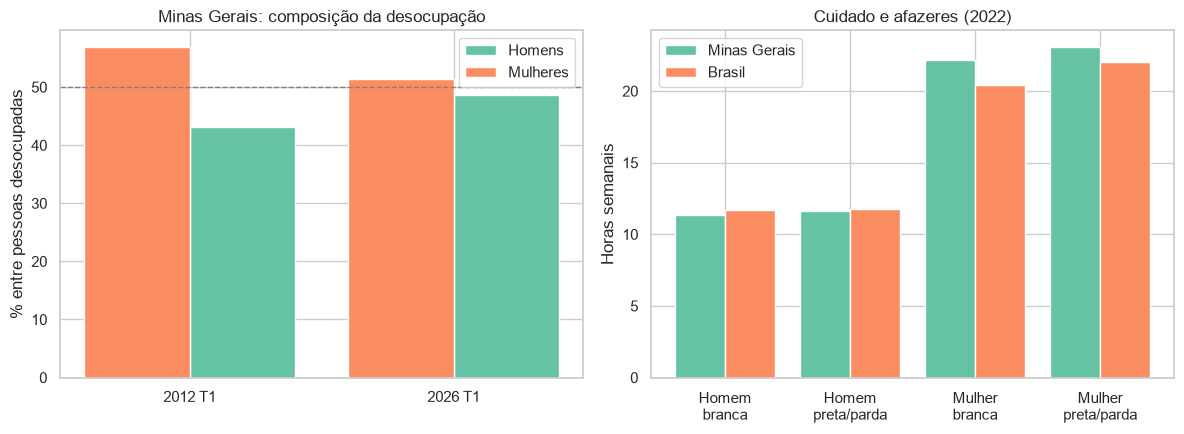

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

anos = ["2012 T1", "2026 T1"]
axes[0].bar(anos, [linha["homens_2012"], linha["homens_2026"]], label="Homens", width=0.4, align="edge")
axes[0].bar(anos, [linha["mulheres_2012"], linha["mulheres_2026"]], label="Mulheres", width=-0.4, align="edge")
axes[0].axhline(50, color="gray", linestyle="--", linewidth=1)
axes[0].set_ylabel("% entre pessoas desocupadas")
axes[0].set_title(f"{ESTADO}: composição da desocupação")
axes[0].legend()

grupos = ["Homem\nbranca", "Homem\npreta/parda", "Mulher\nbranca", "Mulher\npreta/parda"]
valores_ro = [
    linha["horas_homem_branca"], linha["horas_homem_preta_parda"],
    linha["horas_mulher_branca"], linha["horas_mulher_preta_parda"],
]
valores_br = [
    brasil["horas_homem_branca"], brasil["horas_homem_preta_parda"],
    brasil["horas_mulher_branca"], brasil["horas_mulher_preta_parda"],
]
x = range(len(grupos))
axes[1].bar([i - 0.2 for i in x], valores_ro, width=0.4, label=ESTADO)
axes[1].bar([i + 0.2 for i in x], valores_br, width=0.4, label="Brasil")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(grupos)
axes[1].set_ylabel("Horas semanais")
axes[1].set_title("Cuidado e afazeres (2022)")
axes[1].legend()

fig.tight_layout()
plt.show()

### Análise quantitativa (Rondônia)

- Em **2012 T1**, as mulheres já eram maioria das pessoas desocupadas (**56,6%** contra 43,4% de homens).
- Em **2026 T1**, essa participação sobe para **67,0%** (homens 33,0%). É a **maior participação feminina entre desocupados** das 27 UFs e a **maior alta** do período (**+10,4 pp**).
- A composição da desocupação não é taxa de desemprego: o dado diz *quem são* as pessoas desocupadas, não *qual fração da PEA* está desocupada.
- Na PNAD Contínua 2022, as mulheres em Rondônia dedicam cerca de **20 a 21 horas** semanais a cuidados/afazeres; os homens, cerca de **12 a 12,5 horas**. A brecha é da ordem de **8 a 9 horas** por semana.
- Mulheres pretas ou pardas têm a carga um pouco maior do que as brancas (21,1 h × 20,4 h). O mesmo padrão aparece no Brasil, com brecha nacional ainda maior para mulheres pretas ou pardas (**22,0 h** no país).
- Em Rondônia a carga feminina é **parecida com a média brasileira**; o que destoa é o salto da participação das mulheres entre as desocupadas.

### Análise qualitativa (Rondônia)

Os dois indicadores apontam para uma **penalidade dupla** no mercado de trabalho: as mulheres seguem responsáveis pela maior parte do trabalho não pago de cuidado e, no recorte da desocupação, passaram a ser ainda mais visíveis entre quem está sem ocupação.

Uma leitura possível é que a jornada de cuidado reduz disponibilidade (horário, deslocamento, informalidade) e torna mais difícil manter ou retomar um trabalho remunerado. Isso não prova causalidade: a Tabela 5 não informa se o desemprego feminino subiu ou se o masculino caiu mais rápido, e as horas de 2022 são calculadas **só para quem declarou** ter feito essas atividades.

Entre as 27 UFs, a correlação entre horas de cuidado das mulheres e a participação feminina na desocupação de 2026 é **quase nula**. O padrão não é “quem cuida mais, desocupa mais” em todo o país: Rondônia é um **caso extremo**, não a regra. Acre, Distrito Federal, Goiás e Paraná viram a participação feminina entre desocupados **cair** (entre −6 e −8 pp). Tocantins, ao contrário, também sobe bastante (+9,1 pp), mas partindo de uma situação em que as mulheres ainda eram minoria em 2012 (44,7%).

O cruzamento com a Tabela 1.1.1 mostra que, mesmo sem correlação nacional forte, a divisão sexual do trabalho doméstico **não se inverteu**: em Rondônia as mulheres seguem com jornada doméstica quase o dobro da dos homens.

**Limites.** Anos diferentes (2012, 2022, 2026); média de horas sem peso populacional por cor/raça; 27 UFs sem ponderar população; composição da desocupação ≠ taxa. O exercício mostra associação e um caso extremo, não um modelo causal.